**← Previous:** [Drift](11_drift.ipynb)  

```text
Capital analysis
├── Import & Setup
├── PD and LGD estimation
└── Stress-testing        
```

#### Import & Setup 

In [1]:
# Init work dir

from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
# Standard modules

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Framework

from src.decisioning import aggregate_el_on_pd, estimate_capital_reduction, show_approval_vs_reduction
from src.decisioning import estimate_reverse_capital_stress, show_pd_stress_vs_capital, show_pd_stress_vs_lossdev, ec_summary
from src.feature_engineering import create_target_def12
from src.modelling import apply_pipe_PD, apply_pipe_LGD, estimate_capital
from src.plots import plot_loss_distribution, plot_heatmap
from src.preprocessing import input_load
from src.validation import validate_predictions

# Dataset specific settings

from src import settings_dataset_unsecured as settings

# Configuration

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.expand_frame_repr", False)
from sklearn import set_config; set_config(transform_output="pandas")

In [3]:
# load input file

portfolio = input_load(2019, 2020, column_date=settings.COLUMN_DATE, column_year=settings.COLUMN_YEAR)
portfolio, dr_summary = create_target_def12(portfolio, 
                                            settings.COLUMN_DATE,
                                            settings.COLUMN_YEAR, 
                                            settings.COLUMN_TARGET_DATE,
                                            settings.COLUMN_TARGET, 
                                            verbose=False,
                                            )

#### PD and LGD estimation

In [4]:
# import pipelines

import joblib
pipeline_pd  = joblib.load("../models/PIPELINE_PD_v012_LR_cal_shift-test.pkl")
pipeline_lgd = joblib.load("../models/PIPELINE_LGD_v012_amount.pkl")

In [5]:
# apply pipelines

portfolio = apply_pipe_PD(portfolio, pipeline_pd)
portfolio = apply_pipe_LGD(portfolio, pipeline_lgd)

In [6]:
# validate model output

validate_predictions(portfolio)

----------------------------------------
MODEL OUTPUT VALIDATION
----------------------------------------


,PD,LGD
Min,0.000,0.000
Mean,0.150,0.132
Max,0.595,0.224
NaNs,0.000,0.000


,PD,LGD
Min,2.284632e-18,0.000000
Mean,1.499553e-01,0.132040
Max,5.948402e-01,0.224033
NaNs,0.000000e+00,0.000000


## Stress-testing

#### 1st experiment

In [7]:
# how much should we stress PDs 
# to exceed an economic capital constraint?

pd_stress_factors = np.round(np.arange(1.0, 5.1, 0.1), 1)
capital_stress = estimate_reverse_capital_stress(portfolio, 
                                                 threshold=0.20, 
                                                 stress_factors=pd_stress_factors,
                                                 column_lgd='LossGivenDefault',
                                                 column_def=settings.COLUMN_TARGET,
                                                 column_ead=settings.COLUMN_EAD,
                                                 verbose=False)

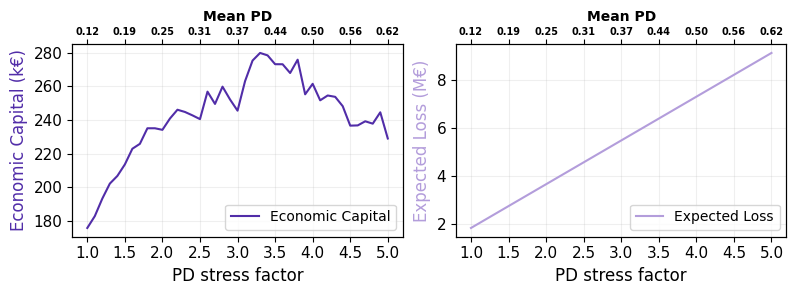

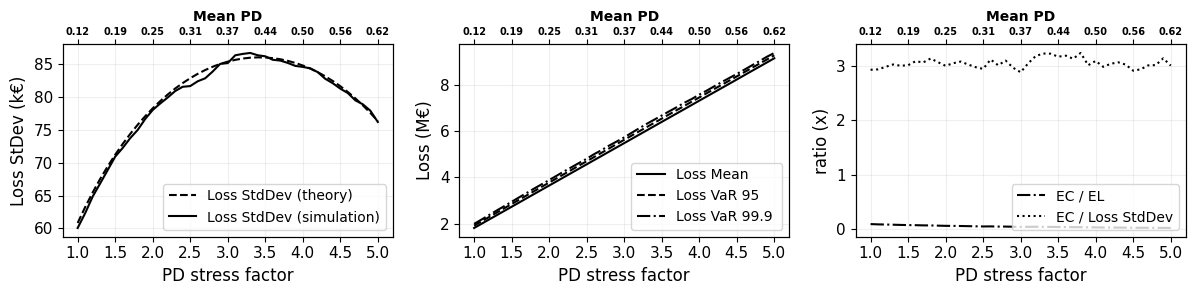

In [8]:
show_1 = show_pd_stress_vs_capital(capital_stress, show_plot=True, invert_y=False)
show_2 = show_pd_stress_vs_lossdev(capital_stress, show_plot=True, invert_y=False)

#### Seeds experiment

In [12]:
# define seeds experiment

pd_stress_factors = np.round(np.arange(1.0, 5.1, 0.1), 1)
def run_reverse_capital_stress_seeds(df=portfolio, threshold=0.20, stress_factors=pd_stress_factors, seeds=None):

    if seeds is None:
        seeds = [42, 123, 456, 789, 2026]

    all_results = []

    for seed in seeds:

        print(f"Running Experiment with seed={seed}")

        results = estimate_reverse_capital_stress(df, 
                                                 threshold, 
                                                 stress_factors,
                                                 column_lgd='LossGivenDefault',
                                                 column_def=settings.COLUMN_TARGET,
                                                 column_ead=settings.COLUMN_EAD,
                                                 verbose=False,
                                                 seed=seed)

        all_results.append(results)

    results_all = pd.concat(
        all_results,
        ignore_index=True
    )

    return results_all

In [13]:
# run experiment (5 seeds 40m, 25 seeds)

seeds = [42, 123, 456, 789, 2026, 17, 83, 256, 512, 1024, 1337, 2025, 3141, 2718, 9001, 111, 222, 333, 444, 555, 678, 987, 1234, 5678, 8765]

results_all = run_reverse_capital_stress_seeds(seeds=seeds)
results_all.to_pickle("../archive/reverse_capital_stress_25seeds.pkl")

Running Experiment with seed=42
Running Experiment with seed=123
Running Experiment with seed=456
Running Experiment with seed=789
Running Experiment with seed=2026
Running Experiment with seed=17
Running Experiment with seed=83
Running Experiment with seed=256
Running Experiment with seed=512
Running Experiment with seed=1024
Running Experiment with seed=1337
Running Experiment with seed=2025
Running Experiment with seed=3141
Running Experiment with seed=2718
Running Experiment with seed=9001
Running Experiment with seed=111
Running Experiment with seed=222
Running Experiment with seed=333
Running Experiment with seed=444
Running Experiment with seed=555
Running Experiment with seed=678
Running Experiment with seed=987
Running Experiment with seed=1234
Running Experiment with seed=5678
Running Experiment with seed=8765


In [14]:
# load experiment results

results_all = pd.read_pickle("../archive/reverse_capital_stress_25seeds.pkl")

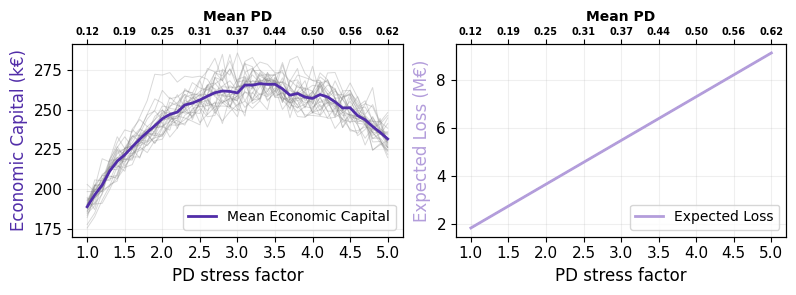

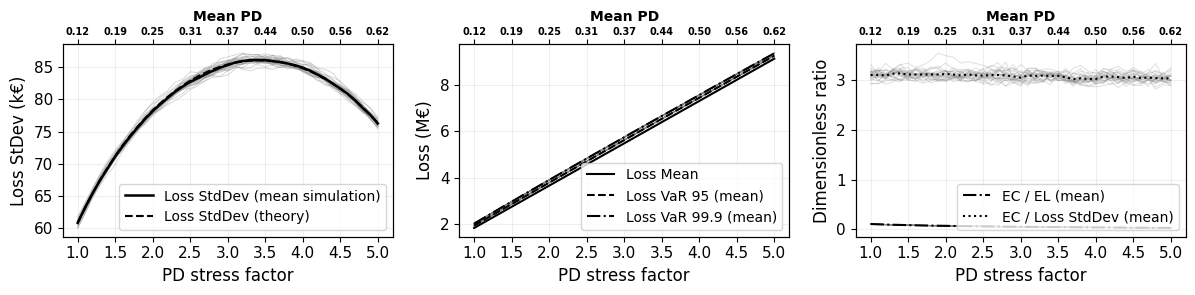

In [15]:
show_1 = show_pd_stress_vs_capital(results_all, show_plot=True, invert_y=False)
show_2 = show_pd_stress_vs_lossdev(results_all, show_plot=True, invert_y=False)

In [16]:
# summarize

summary = ec_summary(results_all, print_table=False)


========== MONTE CARLO STRESS SUMMARY ==========

Number of seeds:             25
Stress scenarios:            41

--- Expected Loss ---
Baseline EL:                 €1,825,808
Final EL:                    €9,129,041
EL increase:                 400.0%

--- Economic Capital ---
Baseline EC:                 €189,105
Maximum mean EC:             €266,268
Peak stress factor:          3.3x
Final EC:                    €231,619
EC change from peak:         -13.0%

--- VaR 99.9% ---
Baseline VaR:                €2,015,026
Final VaR:                   €9,360,509
Baseline VaR CV:             0.30%
Final VaR CV:                0.08%

--- EC variability ---
Baseline EC CV:              3.07%
Peak EC CV:                  2.53%


